# 01 · Explore the overdose data

Work through this top to bottom, one cell at a time (**Shift+Enter**), like running chunks in an R Markdown file.
Every table and plot shows up under the cell that made it. Change things and re-run.

**Kernel:** top-right of VS Code → *Select Kernel* → *Python Environments* → `.venv` (this project's environment).

Rough R ↔ pandas dictionary:

| R / dplyr | pandas |
|---|---|
| `read_csv()` | `pd.read_csv()` |
| `head(df)`, `glimpse(df)` | `df.head()`, `df.info()` |
| `filter(df, x == 1)` | `df[df.x == 1]` or `df.query("x == 1")` |
| `count(df, x)` | `df["x"].value_counts()` |
| `group_by(g) %>% summarise(m = mean(y))` | `df.groupby("g")["y"].mean()` |
| `pivot_wider()` | `df.pivot(index=..., columns=..., values=...)` |
| `ggplot() + geom_line()` | `ax.plot()` (matplotlib) |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run from the repo root so paths like data/raw/... work, and so `src` is importable.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
from src.cdc import load_series, ALL_DRUG, OPIOIDS, SYNTHETIC_OPIOIDS
from src.breaks import fit_no_break, fit_one_break, fit_two_breaks

pd.set_option("display.max_columns", 30, "display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
print(os.getcwd())

/Users/seangee/Documents/Overdose-Addiction


## 1. The raw CDC file, exactly as downloaded

`data/raw/cdc_vsrr_overdose_national_state.csv`: CDC/NCHS *Provisional Drug Overdose Death Counts* (data.cdc.gov `xkb8-kh2a`).

**One row = one state × one month × one drug indicator.** The number in `Data Value` is a **12-month-ending total**:
the row for *2024 / December* is all deaths from Jan–Dec 2024, and the row for *2025 / March* is Apr 2024–Mar 2025.

In [2]:
raw = pd.read_csv("data/raw/cdc_vsrr_overdose_national_state.csv")
print(raw.shape)          # (rows, columns)
raw.head(10)

(86904, 12)


,State,Year,Month,Period,Indicator,Data Value,Percent Complete,Percent Pending Investigation,State Name,Footnote,Footnote Symbol,Predicted Value
0,AK,2015,January,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
1,AK,2015,February,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
2,AK,2015,March,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
3,AK,2015,April,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
4,AK,2015,May,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
5,AK,2015,June,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
6,AK,2015,July,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
7,AK,2015,August,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
8,AK,2015,September,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN
9,AK,2015,October,12 month-ending,Cocaine (T40.5),NaN,100.0,0.0,Alaska,Numbers may differ from published reports usin...,**,NaN


### What indicators (drug categories) and states are in there?

In [3]:
raw["Indicator"].value_counts()

Indicator
Number of Deaths                                                               7344
Number of Drug Overdose Deaths                                                 7344
Percent with drugs specified                                                   7344
Cocaine (T40.5)                                                                7208
Heroin (T40.1)                                                                 7208
Methadone (T40.3)                                                              7208
Natural & semi-synthetic opioids (T40.2)                                       7208
Natural & semi-synthetic opioids, incl. methadone (T40.2, T40.3)               7208
Natural, semi-synthetic, & synthetic opioids, incl. methadone (T40.2-T40.4)    7208
Opioids (T40.0-T40.4,T40.6)                                                    7208
Psychostimulants with abuse potential (T43.6)                                  7208
Synthetic opioids, excl. methadone (T40.4)                        

In [4]:
print(sorted(raw["State"].unique()))   # US = national, YC = New York City (separate from NY)

['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'PR', 'RI', 'SC', 'SD', 'TN', 'TX', 'US', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV', 'WY', 'YC']


## 2. Filter to the national series (like `dplyr::filter`)

Here we do it by hand so you can see it; `load_series()` in `src/cdc.py` does the same thing with safety checks.

In [5]:
us = raw[(raw["State"] == "US") & (raw["Indicator"] == "Opioids (T40.0-T40.4,T40.6)")].copy()
us["date"] = pd.to_datetime(us["Year"].astype(str) + "-" + us["Month"], format="%Y-%B")
us = us.sort_values("date")[["date", "Indicator", "Data Value", "Predicted Value", "Percent Pending Investigation"]]
us.tail(12)

,date,Indicator,Data Value,Predicted Value,Percent Pending Investigation
73428,2025-05-01,"Opioids (T40.0-T40.4,T40.6)",48908.0,49025.0,0.121488
73429,2025-06-01,"Opioids (T40.0-T40.4,T40.6)",48045.0,48142.0,0.115323
73430,2025-07-01,"Opioids (T40.0-T40.4,T40.6)",47460.0,47585.0,0.111005
73431,2025-08-01,"Opioids (T40.0-T40.4,T40.6)",46825.0,47117.0,0.108586
73432,2025-09-01,"Opioids (T40.0-T40.4,T40.6)",46415.0,46699.0,0.107705
73433,2025-10-01,"Opioids (T40.0-T40.4,T40.6)",45922.0,46171.0,0.106878
73434,2025-11-01,"Opioids (T40.0-T40.4,T40.6)",45509.0,45693.0,0.105434
73435,2025-12-01,"Opioids (T40.0-T40.4,T40.6)",45013.0,45065.0,0.102618
73436,2026-01-01,"Opioids (T40.0-T40.4,T40.6)",44145.0,44313.0,0.130204
73437,2026-02-01,"Opioids (T40.0-T40.4,T40.6)",43424.0,43715.0,0.161627


## 3. Plot several drug categories at once

Build a long table (one row per month × indicator), then pivot wide (one column per indicator), the same as `pivot_wider`.
Note the categories **overlap**: fentanyl deaths (T40.4) are inside "Opioids", and one death can involve several drugs. So these lines don't add up.

In [6]:
INDICATORS = [
    "Number of Drug Overdose Deaths",
    "Opioids (T40.0-T40.4,T40.6)",
    "Synthetic opioids, excl. methadone (T40.4)",
    "Psychostimulants with abuse potential (T43.6)",
    "Cocaine (T40.5)",
    "Heroin (T40.1)",
    "Natural & semi-synthetic opioids (T40.2)",
]
long = pd.concat([load_series(indicator=i).assign(indicator=i) for i in INDICATORS])
wide = long.pivot(index="date", columns="indicator", values="deaths")[INDICATORS]
wide.tail()

indicator,Number of Drug Overdose Deaths,"Opioids (T40.0-T40.4,T40.6)","Synthetic opioids, excl. methadone (T40.4)",Psychostimulants with abuse potential (T43.6),Cocaine (T40.5),Heroin (T40.1),Natural & semi-synthetic opioids (T40.2)
date,,,,,,,
2025-12-01,70646,45013,38462,26260,19933,2060,7142
2026-01-01,69544,44145,37683,25798,19765,1994,6995
2026-02-01,68689,43424,36911,25399,19641,1931,6959
2026-03-01,67104,42098,35603,24784,19236,1836,6830
2026-04-01,65726,41031,34523,24153,18965,1738,6758


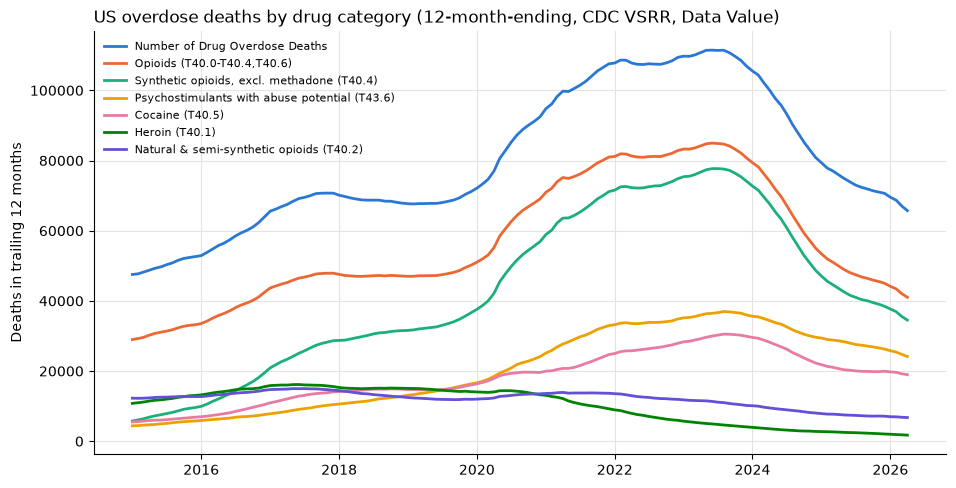

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for color, ind in zip(COLORS, INDICATORS):
    ax.plot(wide.index, wide[ind], color=color, lw=2, label=ind)
ax.set_ylabel("Deaths in trailing 12 months")
ax.set_title("US overdose deaths by drug category (12-month-ending, CDC VSRR, Data Value)", loc="left")
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.show()

## 4. Break points: try it on any series

Change `INDICATOR` (copy a name from the list in section 1) and re-run. `MIN_SEG` is the shortest segment allowed, in months.
The fit draws three straight-line pieces and picks the two break dates that make the total squared error (SSE) smallest.

breaks: 2020-07, 2023-06
SSE  no break 25,943,664,297 | one break (@2023-07) 2,620,278,855 | two breaks 1,006,399,771


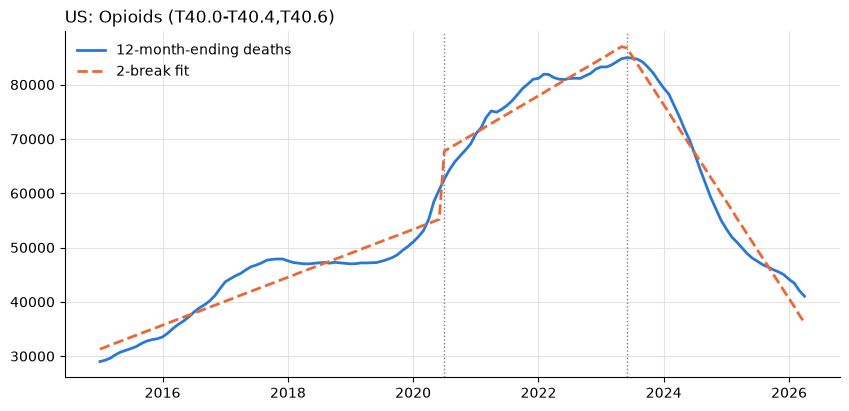

In [8]:
INDICATOR = "Opioids (T40.0-T40.4,T40.6)"
STATE = "US"
MIN_SEG = 12

s = load_series(state=STATE, indicator=INDICATOR)
y = s["deaths"].to_numpy(float)
tau1, tau2, fitted, sse2 = fit_two_breaks(y, min_seg=MIN_SEG)
tau, _, sse1 = fit_one_break(y, min_seg=MIN_SEG)
_, sse0 = fit_no_break(y)

print(f"breaks: {s.date[tau1]:%Y-%m}, {s.date[tau2]:%Y-%m}")
print(f"SSE  no break {sse0:,.0f} | one break (@{s.date[tau]:%Y-%m}) {sse1:,.0f} | two breaks {sse2:,.0f}")

fig, ax = plt.subplots()
ax.plot(s.date, s.deaths, color=COLORS[0], lw=2, label="12-month-ending deaths")
ax.plot(s.date, fitted, color=COLORS[1], lw=2, ls="--", label="2-break fit")
for t in (tau1, tau2):
    ax.axvline(s.date[t], color="gray", ls=":", lw=1)
ax.set_title(f"{STATE}: {INDICATOR}", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.show()

## 5. Compare states

Raw **counts**, not rates: this file has no population column, so big states look big. For a fair comparison you'd divide by
population (not in this file; that's a later step). Some states have missing drug-specific months (CDC marks them low quality, mostly early years).
`allow_missing=True` keeps those as blanks, so the line just has a gap; nothing is filled in. The cell prints how many months each state is missing.

WV: 0 missing months
OH: 3 missing months (2015-01 to 2015-03)


CA: 53 missing months (2015-01 to 2019-05)
FL: 72 missing months (2015-01 to 2026-04)


NY: 0 missing months


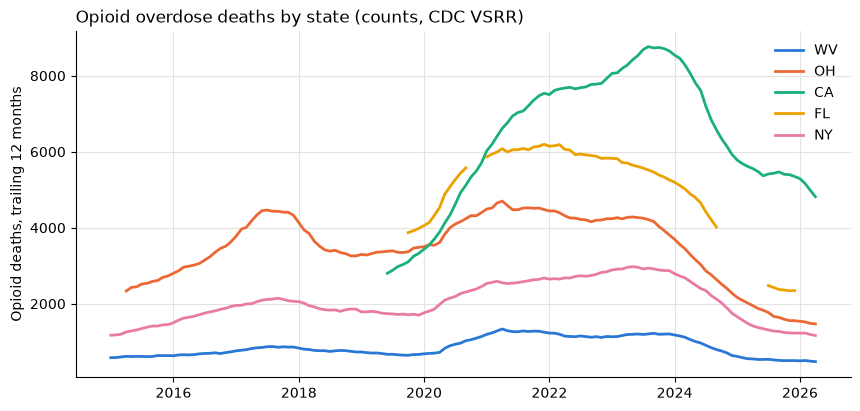

In [9]:
STATES = ["WV", "OH", "CA", "FL", "NY"]
fig, ax = plt.subplots()
for color, st in zip(COLORS, STATES):
    d = load_series(state=st, indicator=OPIOIDS, allow_missing=True)
    miss = d[d.deaths.isna()]
    print(f"{st}: {len(miss)} missing months" + (f" ({miss.date.min():%Y-%m} to {miss.date.max():%Y-%m})" if len(miss) else ""))
    ax.plot(d.date, d.deaths, color=color, lw=2, label=st)
ax.set_ylabel("Opioid deaths, trailing 12 months")
ax.set_title("Opioid overdose deaths by state (counts, CDC VSRR)", loc="left")
ax.legend(frameon=False)
plt.show()

## 6. Deaths vs. self-reported misuse (the research-question plot)

**Provenance of the NSDUH numbers:** typed in by hand from SAMHSA's published NSDUH reports, *not* computed from microdata here,
and not yet re-checked. 2023 is blank because it's published only as a range (3.0–3.1).
Both series are indexed to 2021 = 100 so they share one axis.

,year,opioid_misuse_pct,deaths,deaths_idx,misuse_idx
0,2021,3.2,80997,100.0,100.0
1,2022,3.0,82851,102.3,93.8
2,2023,NaN,80719,99.7,NaN
3,2024,2.7,55007,67.9,84.4


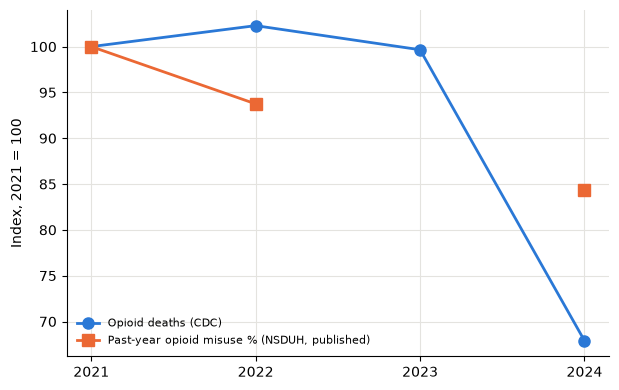

In [10]:
nsduh = pd.DataFrame({"year": [2021, 2022, 2023, 2024],
                      "opioid_misuse_pct": [3.2, 3.0, np.nan, 2.7]})
deaths_dec = load_series(indicator=OPIOIDS).query("month == 12")[["year", "deaths"]]  # Dec value = calendar-year total
comp = nsduh.merge(deaths_dec, on="year")
comp["deaths_idx"] = 100 * comp.deaths / comp.deaths.iloc[0]
comp["misuse_idx"] = 100 * comp.opioid_misuse_pct / comp.opioid_misuse_pct.iloc[0]
display(comp.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(comp.year, comp.deaths_idx, "o-", color=COLORS[0], lw=2, ms=8, label="Opioid deaths (CDC)")
ax.plot(comp.year, comp.misuse_idx, "s-", color=COLORS[1], lw=2, ms=8, label="Past-year opioid misuse % (NSDUH, published)")
ax.set_xticks(comp.year); ax.set_ylabel("Index, 2021 = 100")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 7. NSDUH 2023 microdata (individual level, kept separate)

`data/raw/nsduh_2023/NSDUH_2023.dta`: one row per survey respondent (56,705 people, 2,636 variables).
We read only the columns we need. Percentages must use the survey weight `ANALWT2_C`;
an unweighted mean would describe the *sample*, not the US population.
These are point estimates only (no standard errors yet; those need the design variables `VESTR_C` and `VEREP`).

In [11]:
import pyreadstat
cols = ["OPINMYR", "PNRNMYR", "HERYR", "CATAG6", "IRSEX", "ANALWT2_C", "VESTR_C", "VEREP"]
ns, meta = pyreadstat.read_dta("data/raw/nsduh_2023/NSDUH_2023.dta", usecols=cols)
print(ns.shape)
print({c: meta.column_names_to_labels[c] for c in cols})
ns.head()

(56705, 8)
{'OPINMYR': 'RC-OPIOIDS - PAST YEAR MISUSE', 'PNRNMYR': 'RC-PAIN RELIEVERS - PAST YEAR MISUSE', 'HERYR': 'RC-HEROIN - PAST YEAR USE', 'CATAG6': 'RC-AGE CATEGORY RECODE (6 LEVELS)', 'IRSEX': 'SEX AT BIRTH - IMPUTATION REVISED', 'ANALWT2_C': 'FIN PRSN-LEVEL SMPLE WGHT 2', 'VESTR_C': 'VARIANCE STRATUM', 'VEREP': 'VARIANCE PRIMARY SAMPLING UNIT'}


,ANALWT2_C,VESTR_C,VEREP,IRSEX,CATAG6,HERYR,PNRNMYR,OPINMYR
0,3276.469874,40031,2,1,5,0,0,0
1,15630.082955,40021,2,1,4,0,0,0
2,4018.172390,40043,1,2,4,0,0,0
3,10711.709540,40030,2,1,1,0,0,0
4,8195.104779,40023,2,1,5,0,0,0


In [12]:
def wpct(g, var):
    return 100 * np.average(g[var] == 1, weights=g["ANALWT2_C"])

age_labels = meta.variable_value_labels["CATAG6"]
by_age = (ns.groupby("CATAG6")
            .apply(lambda g: pd.Series({"n_respondents": len(g),
                                        "opioid_misuse_pct": wpct(g, "OPINMYR"),
                                        "pain_reliever_misuse_pct": wpct(g, "PNRNMYR"),
                                        "heroin_use_pct": wpct(g, "HERYR")}), include_groups=False)
            .rename(index=age_labels).round(2))
print("All ages 12+: opioid misuse", round(wpct(ns, "OPINMYR"), 2), "%")
by_age

All ages 12+: opioid misuse 3.19 %


,n_respondents,opioid_misuse_pct,pain_reliever_misuse_pct,heroin_use_pct
CATAG6,,,,
1 - 12-17 Years Old,11572.0,2.28,2.27,0.01
2 - 18-25 Years Old,13587.0,2.66,2.65,0.07
3 - 26-34 Years Old,9171.0,4.08,3.95,0.37
4 - 35-49 Years Old,12355.0,4.13,3.82,0.60
5 - 50-64 Years Old,4960.0,3.46,3.42,0.14
6 - 65 or Older,5060.0,1.93,1.88,0.04


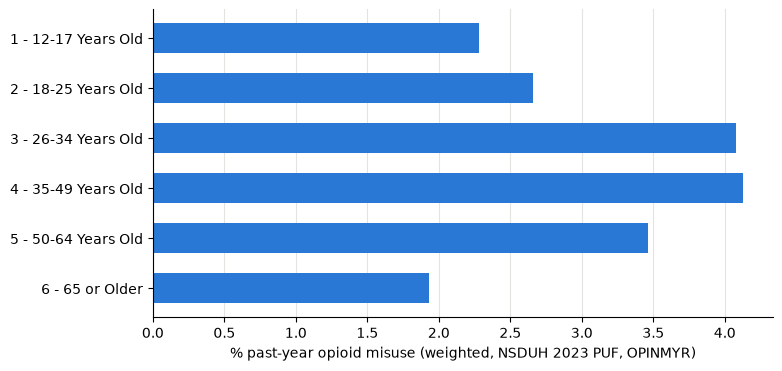

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(by_age.index.astype(str), by_age["opioid_misuse_pct"], color=COLORS[0], height=0.6)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("% past-year opioid misuse (weighted, NSDUH 2023 PUF, OPINMYR)")
plt.show()

## 8. County deaths + SVI (area level, kept separate from NSDUH)

County file values are 12-month-ending all-drug deaths (no opioid split). Fixes needed before joining (see `data/DATA_PROFILE.md`):
zero-pad FIPS, drop duplicated Virginia FIPS rows, and note Connecticut won't match.
Suppressed counties (1–9 deaths) drop out, so small rural counties are under-represented. **Zeros are real zeros** (CDC shows 0 but hides 1–9),
which is why there's a row of dots on y = 0 and nothing just above it. Keep that in mind when reading the scatter.
Rate denominator: `E_TOTPOP` from SVI 2022 (ACS 2018–2022 estimate).

In [14]:
cty = pd.read_csv("data/raw/cdc_vsrr_overdose_county.csv", dtype={"FIPS": str})
cty["FIPS"] = cty["FIPS"].str.zfill(5)
cty = cty[(cty.Year == 2023) & (cty.Month == 12)].drop_duplicates("FIPS")
svi = pd.read_csv("data/raw/svi_2022_us_county.csv", dtype={"FIPS": str})

m = cty.merge(svi[["FIPS", "LOCATION", "E_TOTPOP", "RPL_THEMES", "EP_POV150"]], on="FIPS", how="inner")
m = m.dropna(subset=["Provisional Drug Overdose Deaths"])
m = m[m.RPL_THEMES >= 0]
m["deaths_per_100k"] = 1e5 * m["Provisional Drug Overdose Deaths"] / m["E_TOTPOP"]
print(f"{len(cty)} counties in month; {len(m)} after join + dropping suppressed")
m.sort_values("deaths_per_100k", ascending=False)[["LOCATION", "Provisional Drug Overdose Deaths", "E_TOTPOP", "deaths_per_100k", "RPL_THEMES"]].head(10)

3142 counties in month; 1709 after join + dropping suppressed


,LOCATION,Provisional Drug Overdose Deaths,E_TOTPOP,deaths_per_100k,RPL_THEMES
3077,"Menominee County, Wisconsin",13.0,4279,303.809301,0.5743
3006,"McDowell County, West Virginia",37.0,18911,195.653323,0.8721
1016,"Estill County, Kentucky",27.0,14138,190.974678,0.7604
3037,"Wyoming County, West Virginia",34.0,21237,160.097942,0.5173
1048,"Lee County, Kentucky",11.0,7338,149.904606,0.8492
3010,"Mercer County, West Virginia",88.0,59530,147.824626,0.7343
1207,"Baltimore city, Maryland",846.0,584548,144.727208,0.8565
2988,"Cabell County, West Virginia",134.0,93965,142.606290,0.7276
996,"Breathitt County, Kentucky",19.0,13580,139.911635,0.6962
2491,"Roane County, Tennessee",72.0,53777,133.886234,0.3083


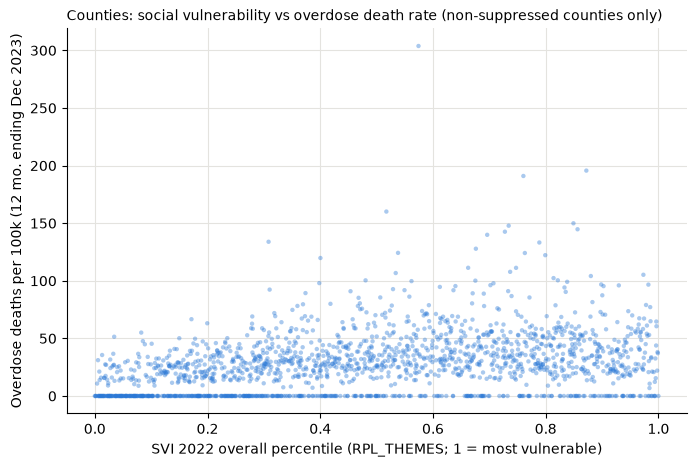

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(m.RPL_THEMES, m.deaths_per_100k, s=10, alpha=0.4, color=COLORS[0], edgecolor="none")
ax.set_xlabel("SVI 2022 overall percentile (RPL_THEMES; 1 = most vulnerable)")
ax.set_ylabel("Overdose deaths per 100k (12 mo. ending Dec 2023)")
ax.set_title("Counties: social vulnerability vs overdose death rate (non-suppressed counties only)", loc="left", fontsize=10)
plt.show()

## Your turn

Ideas to try (all just edits + re-run):
- Section 4: switch `INDICATOR` to `"Synthetic opioids, excl. methadone (T40.4)"` or a state like `"WV"`.
- Section 4: change `MIN_SEG` to 6 or 24 and see whether the break dates move.
- Section 7: replace `CATAG6` with `IRSEX` to break misuse down by sex.
- Section 8: swap `RPL_THEMES` for `EP_POV150` (% below 150% poverty).